# 📊 Avaliação de Métricas e Curvas YOLOv5 para Faster R-CNN e SSD

Este notebook foi desenvolvido especificamente para carregar os pesos já treinados (`best.pt`) salvos no Google Drive dos modelos **Faster R-CNN** e **SSD**, e gerar **as mesmas curvas e matriz de confusão do YOLOv5**:

1. 🎯 **Matriz de Confusão** (`confusion_matrix.png`) - Normalizada, com suporte a classes reais e classe *background*.
2. 📈 **Curva Precision-Confiança** (`P_curve.png`)
3. 📈 **Curva Recall-Confiança** (`R_curve.png`)
4. 📈 **Curva F1-Score-Confiança** (`F1_curve.png`)
5. 📈 **Curva Precision-Recall** (`PR_curve.png`) - Com indicação de mAP@0.5 e área por classe.
6. 🖼️ **Inferência Prática Visual** (Original vs Ground Truth vs Predição da IA).

---
### ⚙️ Como usar:
1. Conecte o ambiente em uma GPU (Ambiente de Execução > Alterar tipo de ambiente de execução > T4 GPU).
2. Execute as células sequencialmente.
3. Na célula **Configuração**, defina qual modelo avaliar (`MODELO_ESCOLHIDO = "FasterRCNN"` ou `"SSD"`).
4. O notebook detectará automaticamente a pasta do treino mais recente no seu Drive (ou você pode especificar um caminho customizado).
5. Todos os gráficos gerados serão salvos diretamente na pasta do modelo no Google Drive (`.../Teste_Final/`) e exibidos na tela.


In [1]:
# Verificar o status da GPU para garantir que o Colab alocou a placa de vídeo
!nvidia-smi


Sun Sep 20 10:38:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Instalar bibliotecas necessárias
!pip install torch torchvision seaborn matplotlib tqdm pyyaml -q

from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')
print("✅ Google Drive montado com sucesso!")


Mounted at /content/drive
✅ Google Drive montado com sucesso!


In [3]:
# ==============================================================================
# MOTOR MATEMÁTICO DE MÉTRICAS E PLOTAGEM DO YOLOV5
# ==============================================================================
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

# Compatibilidade NumPy 1.x e 2.0+ (trapezoid substituiu trapz)
trapezoid = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def box_iou(box1, box2):
    """Calcula matriz de IoU entre duas listas de caixas [x1, y1, x2, y2]."""
    if box1.shape[0] == 0 or box2.shape[0] == 0:
        return torch.zeros((box1.shape[0], box2.shape[0]), dtype=torch.float32, device=box1.device)
    area1 = (box1[:, 2] - box1[:, 0]) * (box1[:, 3] - box1[:, 1])
    area2 = (box2[:, 2] - box2[:, 0]) * (box2[:, 3] - box2[:, 1])
    lt = torch.max(box1[:, None, :2], box2[:, :2])
    rb = torch.min(box1[:, None, 2:], box2[:, 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[:, :, 0] * wh[:, :, 1]
    union = area1[:, None] + area2 - inter
    return inter / (union + 1e-16)

def process_batch(detections, labels, iouv):
    """Determina True Positives para cada limiar de IoU (IoU 0.50 a 0.95)."""
    correct = np.zeros((detections.shape[0], iouv.shape[0]), dtype=bool)
    if detections.shape[0] == 0 or labels.shape[0] == 0:
        return torch.tensor(correct, dtype=torch.bool, device=iouv.device)

    iou = box_iou(labels[:, 1:], detections[:, :4])
    correct_class = labels[:, 0:1] == detections[:, 5]

    for i in range(len(iouv)):
        matches_idx = torch.where((iou >= iouv[i]) & correct_class)
        if matches_idx[0].shape[0]:
            matches = torch.cat(
                (torch.stack(matches_idx, 1), iou[matches_idx[0], matches_idx[1]][:, None]),
                1,
            ).cpu().numpy()
            if matches_idx[0].shape[0] > 1:
                matches = matches[matches[:, 2].argsort()[::-1]]
                matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
                matches = matches[matches[:, 2].argsort()[::-1]]
                matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
            correct[matches[:, 1].astype(int), i] = True

    return torch.tensor(correct, dtype=torch.bool, device=iouv.device)

def smooth(y, f=0.05):
    """Suavização de curva estilo YOLOv5."""
    nf = round(len(y) * f * 2) // 2 + 1
    p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0)
    return np.convolve(yp, np.ones(nf) / nf, mode="valid")

def compute_ap(recall, precision):
    """Calcula AP via interpolação de 101 pontos do COCO."""
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    ap = trapezoid(np.interp(x, mrec, mpre), x)
    return ap, mpre, mrec

def plot_pr_curve(px, py, ap, save_dir="pr_curve.png", names=None):
    """Gera o gráfico da curva Precision-Recall idêntico ao YOLOv5."""
    names = names if names is not None else {}
    save_path = Path(save_dir)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(1, 1, figsize=(9, 6), tight_layout=True)
    py_stack = np.stack(py, axis=1) if len(py) > 0 else np.zeros((len(px), len(names)))

    if 0 < len(names) < 21:
        for i, y in enumerate(py_stack.T):
            class_name = names.get(i, f"class_{i}")
            ax.plot(px, y, linewidth=1, label=f"{class_name} {ap[i, 0]:.3f}")
    else:
        ax.plot(px, py_stack, linewidth=1, color="gray")

    mean_ap = ap[:, 0].mean() if len(ap) > 0 else 0.0
    ax.plot(px, py_stack.mean(1), linewidth=3, color="blue", label=f"all classes {mean_ap:.3f} mAP@0.5")
    ax.set_xlabel("Recall", fontsize=12)
    ax.set_ylabel("Precision", fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", frameon=True)
    ax.set_title("Precision-Recall Curve", fontsize=14, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    fig.savefig(save_path, dpi=250, bbox_inches="tight")
    plt.close(fig)

def plot_mc_curve(px, py, save_dir="mc_curve.png", names=None, xlabel="Confidence", ylabel="Metric"):
    """Gera curvas de Métrica vs Confiança (P_curve, R_curve, F1_curve) idênticas ao YOLOv5."""
    names = names if names is not None else {}
    save_path = Path(save_dir)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(1, 1, figsize=(9, 6), tight_layout=True)

    if 0 < len(names) < 21:
        for i, y in enumerate(py):
            class_name = names.get(i, f"class_{i}")
            ax.plot(px, y, linewidth=1, label=f"{class_name}")
    else:
        ax.plot(px, py.T, linewidth=1, color="gray")

    y_mean = smooth(py.mean(0), 0.05) if len(py) > 0 else np.zeros_like(px)
    best_idx = y_mean.argmax() if len(y_mean) > 0 else 0
    best_val = y_mean[best_idx] if len(y_mean) > 0 else 0.0
    best_conf = px[best_idx] if len(px) > 0 else 0.0

    ax.plot(px, y_mean, linewidth=3, color="blue", label=f"all classes {best_val:.2f} at {best_conf:.3f}")
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", frameon=True)
    ax.set_title(f"{ylabel}-Confidence Curve", fontsize=14, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    fig.savefig(save_path, dpi=250, bbox_inches="tight")
    plt.close(fig)

def ap_per_class(tp, conf, pred_cls, target_cls, plot=False, save_dir=".", names=(), eps=1e-16, prefix=""):
    """Computa métricas por classe e gera os 4 gráficos de curvas."""
    i = np.argsort(-conf)
    tp, conf, pred_cls = tp[i], conf[i], pred_cls[i]

    unique_classes, nt = np.unique(target_cls, return_counts=True)
    nc = len(names) if len(names) > 0 else len(unique_classes)

    px, py = np.linspace(0, 1, 1000), []
    ap = np.zeros((nc, tp.shape[1] if tp.ndim > 1 else 1))
    p = np.zeros((nc, 1000))
    r = np.zeros((nc, 1000))

    for ci, c in enumerate(range(nc)):
        idx_pred = pred_cls == c
        n_l = nt[unique_classes == c][0] if c in unique_classes else 0
        n_p = idx_pred.sum()

        if n_p == 0 or n_l == 0:
            continue

        fpc = (1 - tp[idx_pred]).cumsum(0)
        tpc = tp[idx_pred].cumsum(0)

        recall = tpc / (n_l + eps)
        r[ci] = np.interp(-px, -conf[idx_pred], recall[:, 0], left=0)

        precision = tpc / (tpc + fpc)
        p[ci] = np.interp(-px, -conf[idx_pred], precision[:, 0], left=1)

        for j in range(tp.shape[1]):
            ap[ci, j], mpre, mrec = compute_ap(recall[:, j], precision[:, j])
            if plot and j == 0:
                py.append(np.interp(px, mrec, mpre))

    f1 = 2 * p * r / (p + r + eps)

    if plot:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        plot_pr_curve(px, py, ap, save_path / f"{prefix}PR_curve.png", names)
        plot_mc_curve(px, f1, save_path / f"{prefix}F1_curve.png", names, ylabel="F1")
        plot_mc_curve(px, p, save_path / f"{prefix}P_curve.png", names, ylabel="Precision")
        plot_mc_curve(px, r, save_path / f"{prefix}R_curve.png", names, ylabel="Recall")

    i = smooth(f1.mean(0), 0.1).argmax() if f1.shape[1] > 0 else 0
    p_opt, r_opt, f1_opt = p[:, i], r[:, i], f1[:, i]
    tp_count = (r_opt * (np.array([nt[unique_classes == c][0] if c in unique_classes else 0 for c in range(nc)]))).round()
    fp_count = (tp_count / (p_opt + eps) - tp_count).round()

    return tp_count, fp_count, p_opt, r_opt, f1_opt, ap, unique_classes.astype(int)

class ConfusionMatrix:
    """Matriz de confusão com suporte a classe background idêntica ao YOLOv5."""
    def __init__(self, nc, conf=0.25, iou_thres=0.45):
        self.nc = nc
        self.conf = conf
        self.iou_thres = iou_thres
        self.matrix = np.zeros((nc + 1, nc + 1))

    def process_batch(self, detections, labels):
        if detections is None or detections.shape[0] == 0:
            if labels is not None and labels.shape[0] > 0:
                gt_classes = labels[:, 0].int()
                for gc in gt_classes:
                    self.matrix[self.nc, gc] += 1
            return

        if labels is None or labels.shape[0] == 0:
            detections = detections[detections[:, 4] > self.conf]
            detection_classes = detections[:, 5].int()
            for dc in detection_classes:
                self.matrix[dc, self.nc] += 1
            return

        detections = detections[detections[:, 4] > self.conf]
        if detections.shape[0] == 0:
            gt_classes = labels[:, 0].int()
            for gc in gt_classes:
                self.matrix[self.nc, gc] += 1
            return

        gt_classes = labels[:, 0].int()
        detection_classes = detections[:, 5].int()
        iou = box_iou(labels[:, 1:], detections[:, :4])

        matches_idx = torch.where(iou > self.iou_thres)
        if matches_idx[0].shape[0]:
            matches = torch.cat(
                (torch.stack(matches_idx, 1), iou[matches_idx[0], matches_idx[1]][:, None]),
                1,
            ).cpu().numpy()
            if matches_idx[0].shape[0] > 1:
                matches = matches[matches[:, 2].argsort()[::-1]]
                matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
                matches = matches[matches[:, 2].argsort()[::-1]]
                matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
        else:
            matches = np.zeros((0, 3))

        n = matches.shape[0] > 0
        m0, m1, _ = matches.transpose().astype(int)
        for i, gc in enumerate(gt_classes):
            j = m0 == i
            if n and sum(j) == 1:
                self.matrix[detection_classes[m1[j]], gc] += 1
            else:
                self.matrix[self.nc, gc] += 1

        if n:
            for i, dc in enumerate(detection_classes):
                if not any(m1 == i):
                    self.matrix[dc, self.nc] += 1

    def plot(self, normalize=True, save_dir="", names=()):
        import seaborn as sn
        save_path = Path(save_dir) / "confusion_matrix.png"
        save_path.parent.mkdir(parents=True, exist_ok=True)

        array = self.matrix / ((self.matrix.sum(0).reshape(1, -1) + 1e-9) if normalize else 1)
        array[array < 0.005] = np.nan

        fig, ax = plt.subplots(1, 1, figsize=(10, 8), tight_layout=True)
        nc, nn = self.nc, len(names)

        labels = (0 < nn < 99) and (nn == nc)
        class_list = [names[i] for i in range(nc)] if isinstance(names, dict) else list(names)
        ticklabels = ([*class_list, "background"]) if labels else "auto"

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sn.heatmap(
                array,
                ax=ax,
                annot=nc < 30,
                annot_kws={"size": 10},
                cmap="Blues",
                fmt=".2f",
                square=True,
                vmin=0.0,
                vmax=1.0,
                xticklabels=ticklabels,
                yticklabels=ticklabels,
            ).set_facecolor((1, 1, 1))

        ax.set_xlabel("True (Gabarito)", fontsize=12, fontweight="bold")
        ax.set_ylabel("Predicted (Predição)", fontsize=12, fontweight="bold")
        ax.set_title("Confusion Matrix", fontsize=14, fontweight="bold")
        fig.savefig(save_path, dpi=250, bbox_inches="tight")
        plt.close(fig)

print("✅ Motor de métricas e plotagem YOLOv5 inicializado com sucesso!")


✅ Motor de métricas e plotagem YOLOv5 inicializado com sucesso!


In [4]:
# ==============================================================================
# DEFINIÇÃO DOS DATASETS (COCO para Faster R-CNN e Pascal VOC para SSD)
# ==============================================================================
import os
import glob
import shutil
import xml.etree.ElementTree as ET
from PIL import Image
import torch
import torchvision
from torchvision.transforms import transforms as T

# --- 1. DATASET FASTER R-CNN (Formato COCO) ---
class FasterRCNNCocoDataset(torchvision.datasets.CocoDetection):
    def __init__(self, root, annFile, transforms=None):
        super(FasterRCNNCocoDataset, self).__init__(root, annFile, transforms=None)
        self.meus_transforms = transforms
        ids_originais = sorted(self.coco.getCatIds())
        self.mapa_seguro_classes = {id_original: idx + 1 for idx, id_original in enumerate(ids_originais)}

    def __getitem__(self, idx):
        img, target_orig = super(FasterRCNNCocoDataset, self).__getitem__(idx)
        largura_orig, altura_orig = img.size
        
        boxes = []
        labels = []
        for ann in target_orig:
            bbox = ann['bbox']
            x_min = max(0.0, min((bbox[0] / largura_orig) * 640, 640.0))
            y_min = max(0.0, min((bbox[1] / altura_orig) * 640, 640.0))
            x_max = max(0.0, min(((bbox[0] + bbox[2]) / largura_orig) * 640, 640.0))
            y_max = max(0.0, min(((bbox[1] + bbox[3]) / altura_orig) * 640, 640.0))
            
            if (x_max - x_min) > 1.0 and (y_max - y_min) > 1.0:
                boxes.append([x_min, y_min, x_max, y_max])
                labels.append(self.mapa_seguro_classes[ann['category_id']])
        
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            
        target = {"boxes": boxes, "labels": labels, "image_id": torch.tensor([idx])}
        if self.meus_transforms:
            img = self.meus_transforms(img)
        return img, target

# --- 2. DATASET SSD (Formato Pascal VOC XML) ---
class CustomSSDDataset(torch.utils.data.Dataset):
    def __init__(self, root, split, transforms=None):
        self.root = root
        self.split = split
        self.transforms = transforms
        self.img_dir = os.path.join(root, "images", split)
        self.xml_dir = os.path.join(root, "annotations_xml", split)
        self.img_files = sorted(glob.glob(os.path.join(self.img_dir, "*.jpg")) + glob.glob(os.path.join(self.img_dir, "*.JPG")))
        self.class_to_id = {
            'person': 1,
            'bicycle': 2,
            'car': 3,
            'motorcycle': 4,
            'bus': 5
        }

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        img = Image.open(img_path).convert("RGB")
        largura_orig, altura_orig = img.size

        xml_name = os.path.basename(img_path).replace('.jpg', '.xml').replace('.JPG', '.xml')
        xml_path = os.path.join(self.xml_dir, xml_name)
        boxes, labels = [], []

        if os.path.exists(xml_path):
            tree = ET.parse(xml_path)
            root_xml = tree.getroot()
            for obj in root_xml.findall('object'):
                nome_classe = obj.find('name').text
                if nome_classe in self.class_to_id:
                    bndbox = obj.find('bndbox')
                    xmin = max(0.0, min((float(bndbox.find('xmin').text) / largura_orig) * 300.0, 300.0))
                    ymin = max(0.0, min((float(bndbox.find('ymin').text) / altura_orig) * 300.0, 300.0))
                    xmax = max(0.0, min((float(bndbox.find('xmax').text) / largura_orig) * 300.0, 300.0))
                    ymax = max(0.0, min((float(bndbox.find('ymax').text) / altura_orig) * 300.0, 300.0))
                    if (xmax - xmin) > 1.0 and (ymax - ymin) > 1.0:
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(self.class_to_id[nome_classe])

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels}
        if self.transforms:
            img = self.transforms(img)
        return img, target

    def __len__(self):
        return len(self.img_files)

def collate_fn(batch):
    return tuple(zip(*batch))

print("✅ Classes de Datasets prontas!")


✅ Classes de Datasets prontas!


In [19]:
# ==============================================================================
# CONFIGURAÇÃO: ESCOLHA DO MODELO E LOCALIZAÇÃO DO BEST.PT
# ==============================================================================

# 1. Escolha o modelo: "FasterRCNN" ou "SSD"
MODELO_ESCOLHIDO = "SSD"  # @param ["FasterRCNN", "SSD"]

# 2. Caminho personalizado do treino (ou None para auto-detectar o treino mais recente no Drive)
# Exemplo de caminho manual:
# CAMINHO_TREINO_CUSTOM = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-27_17h47"

# CAMINHO_TREINO_CUSTOM = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08"

# Treino_faster_rcnn_2026-08-03_21h57
# Treino_faster_rcnn_2026-07-27_17h47

# Treino_ssd_2026-07-31_19h08
# Treino_ssd_2026-07-26_13h17
# Treino_ssd_2026-08-01_12h29
CAMINHO_TREINO_CUSTOM = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08"

# 3. Limiares de avaliação
CONF_THRES = 0.25      # Limiar de confiança para a Matriz de Confusão (padrão YOLOv5: 0.25)
IOU_THRES = 0.45       # Limiar de IoU para matching da Matriz de Confusão (padrão YOLOv5: 0.45)
BATCH_SIZE = 8

# Nomes padronizados das classes (Índices 0..4 do YOLO)
CLASS_NAMES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    4: "bus"
}

print(f"🎯 Modelo selecionado para avaliação: {MODELO_ESCOLHIDO}")


🎯 Modelo selecionado para avaliação: SSD


In [20]:
# ==============================================================================
# LOCALIZAÇÃO DO PESO BEST.PT E DESCOMPACTAÇÃO DO DATASET DE TESTE
# ==============================================================================
import glob
import datetime

# --- 1. LOCALIZAR O BEST.PT NO GOOGLE DRIVE ---
if MODELO_ESCOLHIDO == "FasterRCNN":
    diretorio_drive_base = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN"
    padrao_busca = "Treino_faster_rcnn_*"
    caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/FasterRCNN_dataset.zip"
    pasta_local_dataset = "/content/FasterRCNN_dataset"
else:
    diretorio_drive_base = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD"
    padrao_busca = "Treino_ssd_*"
    caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/SSD_dataset.zip"
    pasta_local_dataset = "/content/SSD_dataset"

if CAMINHO_TREINO_CUSTOM:
    pasta_treino = CAMINHO_TREINO_CUSTOM
    print(f"📌 Usando pasta de treino configurada manualmente: {pasta_treino}")
else:
    pastas_encontradas = glob.glob(os.path.join(diretorio_drive_base, padrao_busca))
    if not pastas_encontradas:
        raise FileNotFoundError(f"❌ Nenhuma pasta encontrada em {diretorio_drive_base} com padrão '{padrao_busca}'.")
    pasta_treino = max(pastas_encontradas, key=os.path.getmtime)
    print(f"✅ Pasta de treino mais recente detectada automaticamente: {os.path.basename(pasta_treino)}")

caminho_best_pt = os.path.join(pasta_treino, "weights", "best.pt")
if not os.path.exists(caminho_best_pt):
    raise FileNotFoundError(f"❌ Arquivo best.pt não encontrado em: {caminho_best_pt}")

# Auditoria do peso
mod_time = datetime.datetime.fromtimestamp(os.path.getmtime(caminho_best_pt)).strftime('%d/%m/%Y às %H:%M:%S')
print(f"📁 Caminho do best.pt: {caminho_best_pt}")
print(f"🕒 Modificado em:       {mod_time}")

# Pasta de saída dos gráficos (salvos no Drive dentro da pasta do próprio treino)
pasta_saida_drive = os.path.join(pasta_treino, "Teste_Final")
os.makedirs(pasta_saida_drive, exist_ok=True)
print(f"💾 Os gráficos gerados serão salvos em: {pasta_saida_drive}")

# --- 2. DESCOMPACTAÇÃO DO DATASET SE NECESSÁRIO ---
if not os.path.exists(pasta_local_dataset):
    print(f"🚚 Copiando {os.path.basename(caminho_zip_drive)} do Drive para o SSD local da VM...")
    zip_temp = f"{pasta_local_dataset}.zip"
    shutil.copy2(caminho_zip_drive, zip_temp)
    print("⚡ Descompactando...")
    !unzip -q {zip_temp} -d {pasta_local_dataset}
    if os.path.exists(zip_temp):
        os.remove(zip_temp)
    print("✅ Dataset descompactado localmente!")
else:
    print("✅ Dataset já está presente na VM local!")

# --- 3. CRIAR DATALOADER DE TESTE ---
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"🚀 Dispositivo de execução: {device}")

if MODELO_ESCOLHIDO == "FasterRCNN":
    transforms_rcnn = T.Compose([T.Resize((640, 640)), T.ToTensor()])
    caminho_test_json = os.path.join(pasta_local_dataset, "annotations", "test.json")
    caminho_test_imgs = os.path.join(pasta_local_dataset, "images", "test")
    test_dataset = FasterRCNNCocoDataset(caminho_test_imgs, caminho_test_json, transforms=transforms_rcnn)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=4)
else:
    transforms_ssd = T.Compose([T.Resize((300, 300)), T.ToTensor()])
    root_dataset = None
    for root, dirs, files in os.walk(pasta_local_dataset):
        if "images" in dirs and "annotations_xml" in dirs:
            root_dataset = root
            break
    if root_dataset is None:
        root_dataset = pasta_local_dataset
    test_dataset = CustomSSDDataset(root_dataset, "test", transforms=transforms_ssd)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=4)

print(f"📊 Quantidade de imagens no conjunto de teste: {len(test_dataset)}")


📌 Usando pasta de treino configurada manualmente: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08
📁 Caminho do best.pt: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/weights/best.pt
🕒 Modificado em:       31/07/2026 às 20:52:33
💾 Os gráficos gerados serão salvos em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/Teste_Final
🚚 Copiando SSD_dataset.zip do Drive para o SSD local da VM...
⚡ Descompactando...
✅ Dataset descompactado localmente!
🚀 Dispositivo de execução: cuda
📊 Quantidade de imagens no conjunto de teste: 1034


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [22]:
# ==============================================================================
# CARREGAMENTO DO MODELO E AVALIAÇÃO COMPLETA
# ==============================================================================
import time
from tqdm import tqdm
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, ssd300_vgg16
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.ssd import SSDClassificationHead

# 1. Instanciação e Carregamento dos Pesos
if MODELO_ESCOLHIDO == "FasterRCNN":
    print("🔧 Construindo arquitetura Faster R-CNN (ResNet50 FPN v2)...")
    model = fasterrcnn_resnet50_fpn_v2(weights=None)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # 6 classes: 0=background, 1..5=objetos
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=6)
else:
    print("🔧 Construindo arquitetura SSD300 (VGG16)...")
    model = ssd300_vgg16(weights=None)
    in_channels = [512, 1024, 512, 256, 256, 256]
    num_anchors = [4, 6, 6, 6, 4, 4]
    # 6 classes: 0=background, 1..5=objetos
    model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes=6)

print(f"📥 Carregando pesos de: {caminho_best_pt}")
checkpoint = torch.load(caminho_best_pt, map_location=device)
if isinstance(checkpoint, dict) and "model" in checkpoint:
    checkpoint = checkpoint["model"]
model.load_state_dict(checkpoint)
model.to(device)
model.eval()
print("✅ Modelo carregado e pronto para avaliação!")

# 2. Estruturas para Coleta das Métricas
nc = len(CLASS_NAMES)  # 5 classes de interesse
iouv = torch.linspace(0.5, 0.95, 10, device=device)
confusion_matrix = ConfusionMatrix(nc=nc, conf=CONF_THRES, iou_thres=IOU_THRES)

stats = []
tempos = []

print("🔍 Executando inferência e avaliando dados de teste...")
with torch.no_grad():
    for images, targets in tqdm(test_loader, desc="Avaliando"):
        images = [img.to(device) for img in images]
        
        t0 = time.time()
        outputs = model(images)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        tempos.append((time.time() - t0) / len(images))

        for output, target in zip(outputs, targets):
            pred_boxes = output["boxes"]
            pred_scores = output["scores"]
            pred_labels = output["labels"]

            gt_boxes = target["boxes"].to(device)
            gt_labels = target["labels"].to(device)

            # CONVERSÃO PARA 0-INDEXADO (YOLOv5 Standard):
            # No Faster R-CNN e SSD, as classes anotadas são 1..5.
            # Convertemos para 0..4 subtraindo 1.
            pred_cls_0idx = (pred_labels - 1).float()
            gt_cls_0idx = (gt_labels - 1).float()

            # Filtrar predições com rótulos válidos (0 a nc-1)
            valid_preds = (pred_cls_0idx >= 0) & (pred_cls_0idx < nc)
            pred_boxes = pred_boxes[valid_preds]
            pred_scores = pred_scores[valid_preds]
            pred_cls_0idx = pred_cls_0idx[valid_preds]

            valid_gts = (gt_cls_0idx >= 0) & (gt_cls_0idx < nc)
            gt_boxes = gt_boxes[valid_gts]
            gt_cls_0idx = gt_cls_0idx[valid_gts]

            # Formato do tensor de detecções para o YOLOv5: [x1, y1, x2, y2, conf, cls]
            if len(pred_boxes) > 0:
                detections = torch.cat([pred_boxes, pred_scores[:, None], pred_cls_0idx[:, None]], dim=1)
            else:
                detections = torch.zeros((0, 6), device=device)

            # Formato do tensor de gabarito para o YOLOv5: [cls, x1, y1, x2, y2]
            if len(gt_boxes) > 0:
                labels_tensor = torch.cat([gt_cls_0idx[:, None], gt_boxes], dim=1)
            else:
                labels_tensor = torch.zeros((0, 5), device=device)

            # 1. Atualiza Matriz de Confusão
            confusion_matrix.process_batch(detections, labels_tensor)

            # 2. Atualiza Pareamento TP em 10 limiares de IoU (0.50 a 0.95)
            correct = process_batch(detections, labels_tensor, iouv)
            stats.append((
                correct.cpu(),
                pred_scores.cpu(),
                pred_cls_0idx.cpu(),
                gt_cls_0idx.cpu()
            ))

# 3. Consolidação e Cálculo das Curvas
print("📊 Computando métricas e gerando gráficos oficiais do YOLOv5...")
stats = [torch.cat(x, 0).numpy() for x in zip(*stats)]

if len(stats) and stats[0].any():
    tp, fp, p, r, f1, ap, unique_classes = ap_per_class(
        *stats,
        plot=True,
        save_dir=pasta_saida_drive,
        names=CLASS_NAMES
    )
    ap50, ap = ap[:, 0], ap.mean(1)
    mp, mr, map50, map = p.mean(), r.mean(), ap50.mean(), ap.mean()
else:
    mp, mr, map50, map = 0.0, 0.0, 0.0, 0.0

# 4. Salva a Matriz de Confusão
confusion_matrix.plot(normalize=True, save_dir=pasta_saida_drive, names=CLASS_NAMES)

tempo_medio_ms = (sum(tempos) / len(tempos)) * 1000

print("" + "=" * 70)
print(f"🏆 RESULTADOS FINAIS - {MODELO_ESCOLHIDO.upper()}")
print("=" * 70)
print(f"⏱️ Tempo Médio por Imagem: {tempo_medio_ms:.2f} ms")
print(f"🎯 Precision Média:        {mp * 100:.2f}%")
print(f"🎯 Recall Médio:           {mr * 100:.2f}%")
print(f"🎯 mAP@0.5:                {map50 * 100:.2f}%")
print(f"🎯 mAP@0.5:0.95:           {map * 100:.2f}%")
print("=" * 70)

# Salva resumo em arquivo de texto no Drive
relatorio_txt = os.path.join(pasta_saida_drive, "relatorio_metricas_yolo.txt")
with open(relatorio_txt, "w", encoding="utf-8") as f:
    f.write(f"Métricas Avaliação YOLOv5 - Modelo: {MODELO_ESCOLHIDO}")
    f.write(f"Checkpoint Utilizado: {caminho_best_pt}")
    f.write(f"Tempo Médio: {tempo_medio_ms:.2f} ms / imagem")
    f.write(f"Precision Média: {mp * 100:.2f}%")
    f.write(f"Recall Médio: {mr * 100:.2f}%")
    f.write(f"mAP@0.5: {map50 * 100:.2f}%")
    f.write(f"mAP@0.5:0.95: {map * 100:.2f}%")
    f.write("Desempenho por Classe (AP@0.5):")
    for ci in range(nc):
        f.write(f" - {CLASS_NAMES.get(ci, f'Class {ci}')}: {ap50[ci] * 100:.2f}%")

print(f"✅ Todos os gráficos e relatórios foram salvos com sucesso em: 👉 {pasta_saida_drive}")


🔧 Construindo arquitetura SSD300 (VGG16)...
📥 Carregando pesos de: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/weights/best.pt
✅ Modelo carregado e pronto para avaliação!
🔍 Executando inferência e avaliando dados de teste...


Avaliando:   0%|          | 0/130 [00:00<?, ?it/s]


AttributeError: Caught AttributeError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_6246/2275482892.py", line 69, in __getitem__
    img = Image.open(img_path).convert("RGB")
          ^^^^^^^^^^
AttributeError: type object 'Image' has no attribute 'open'


📊 Visualizando gráficos de avaliação de: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-27_17h47/Teste_Final


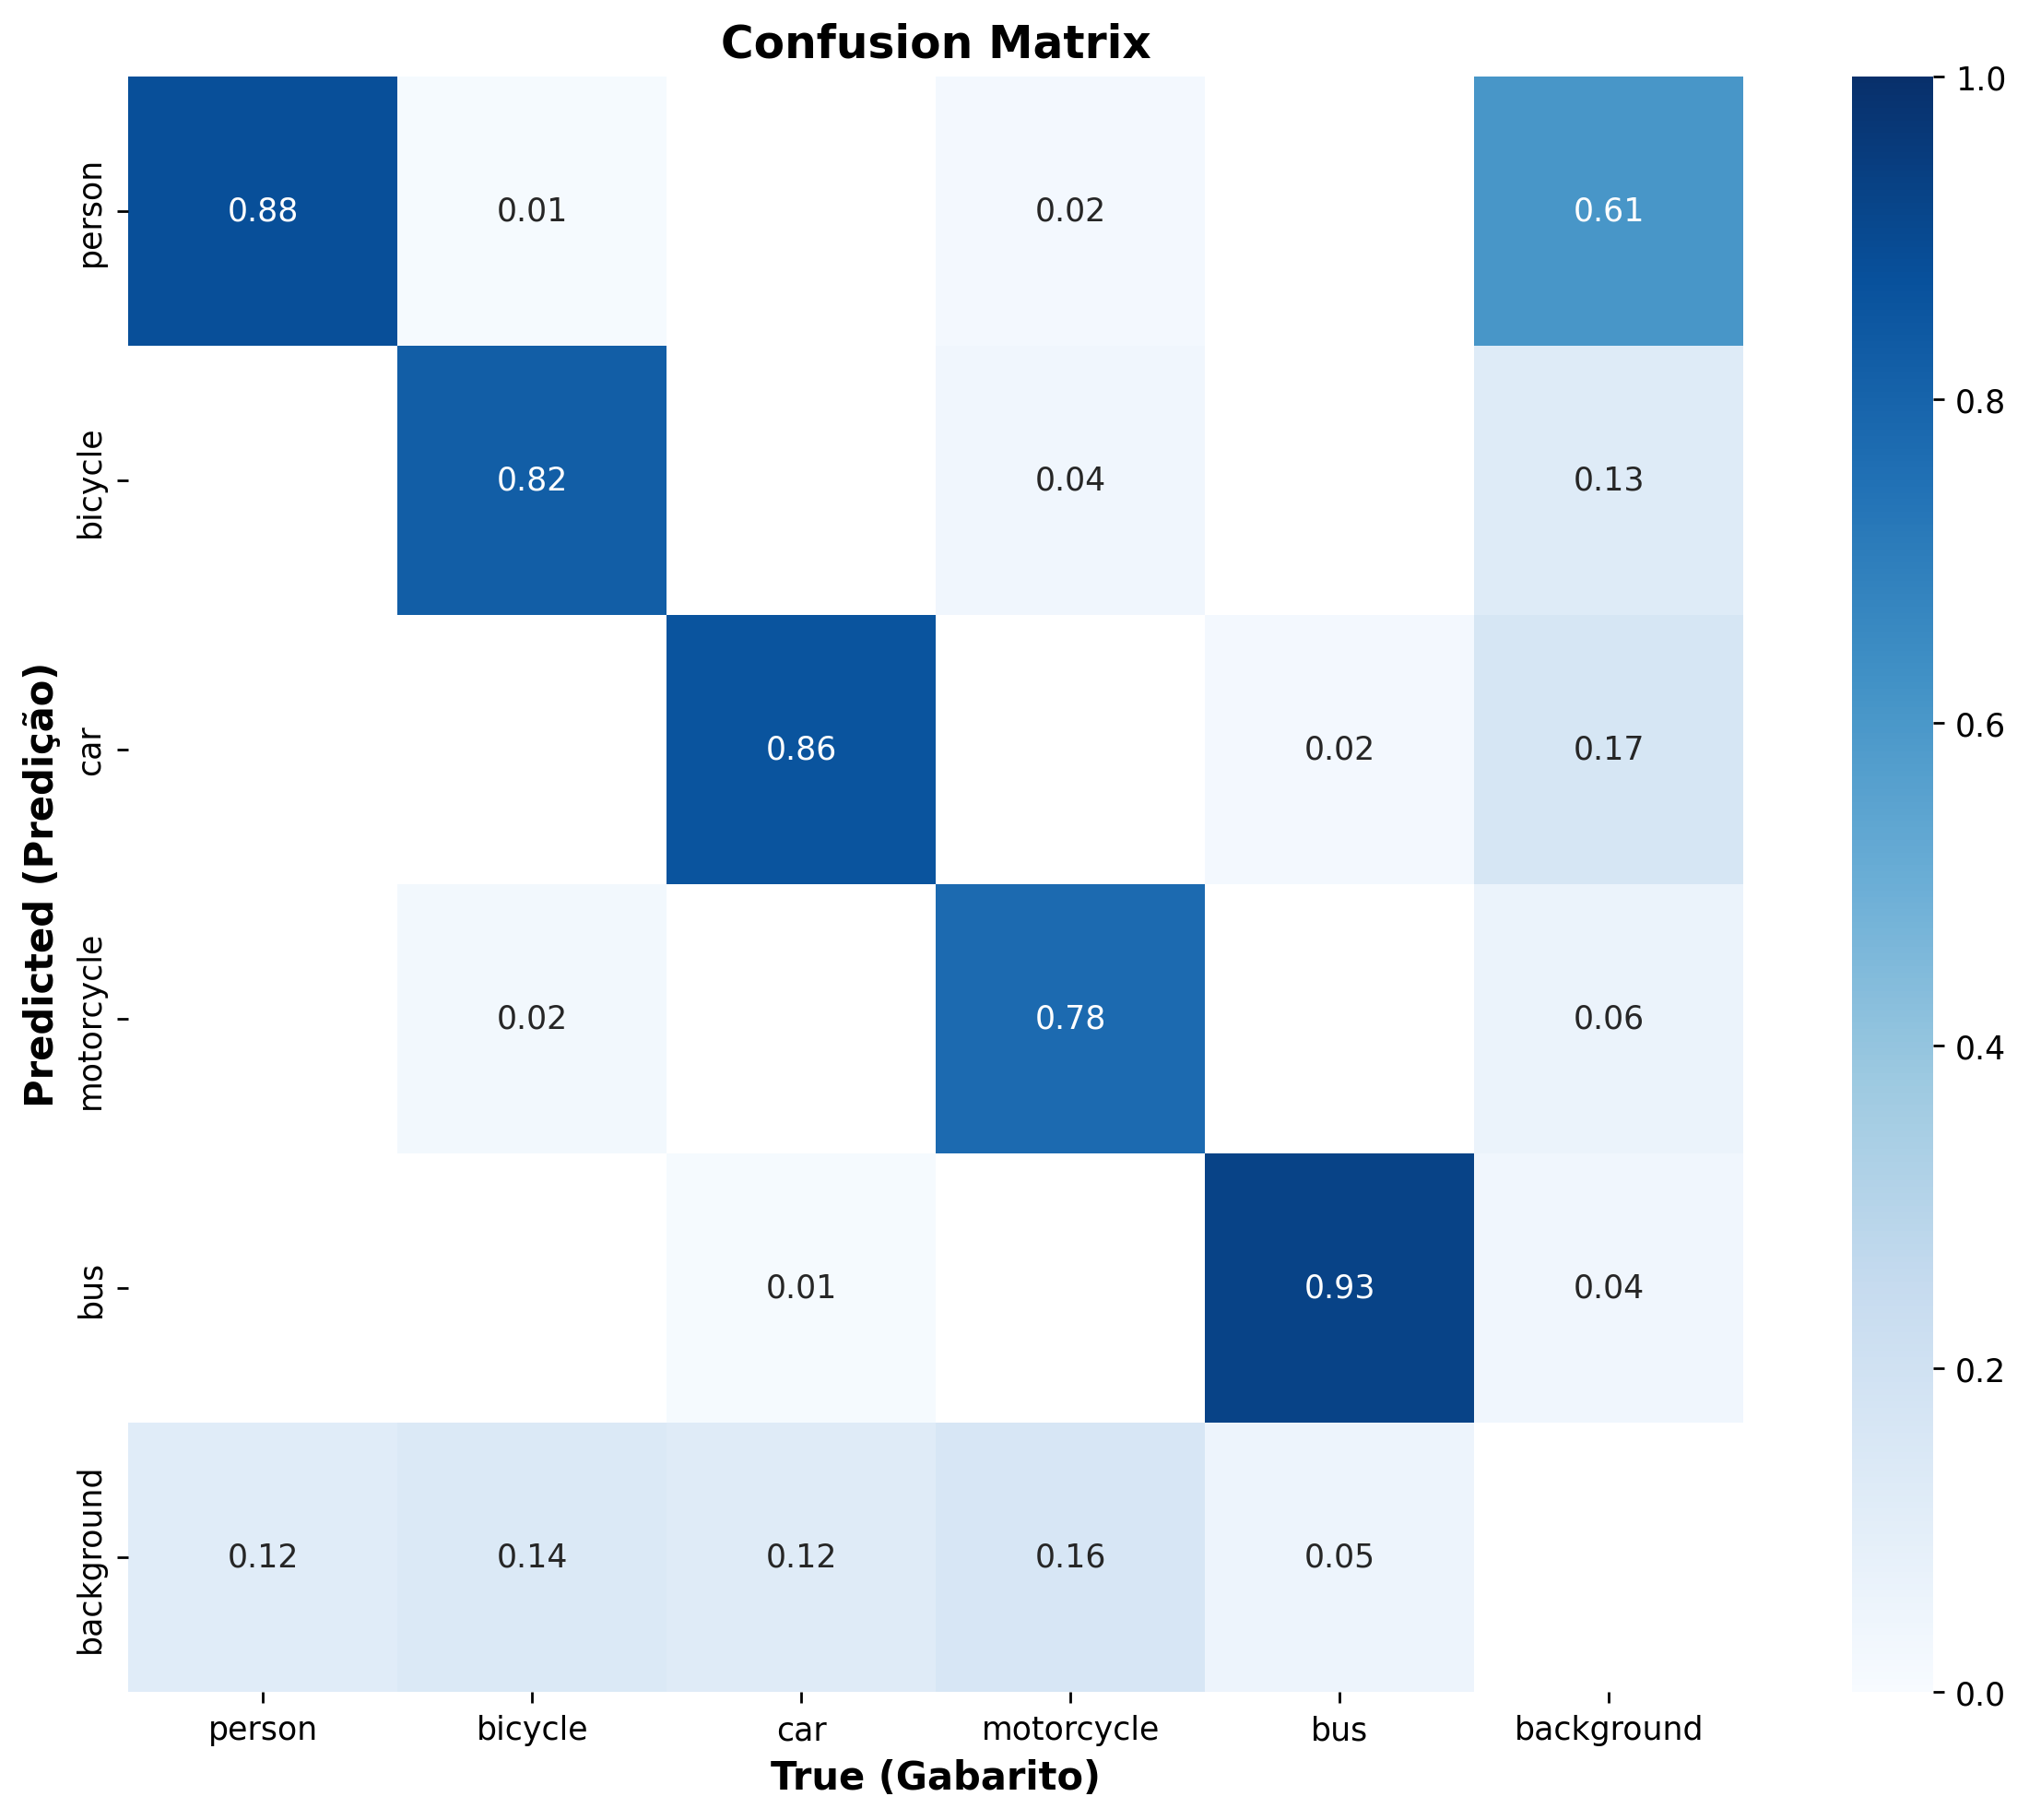

--------------------------------------------------


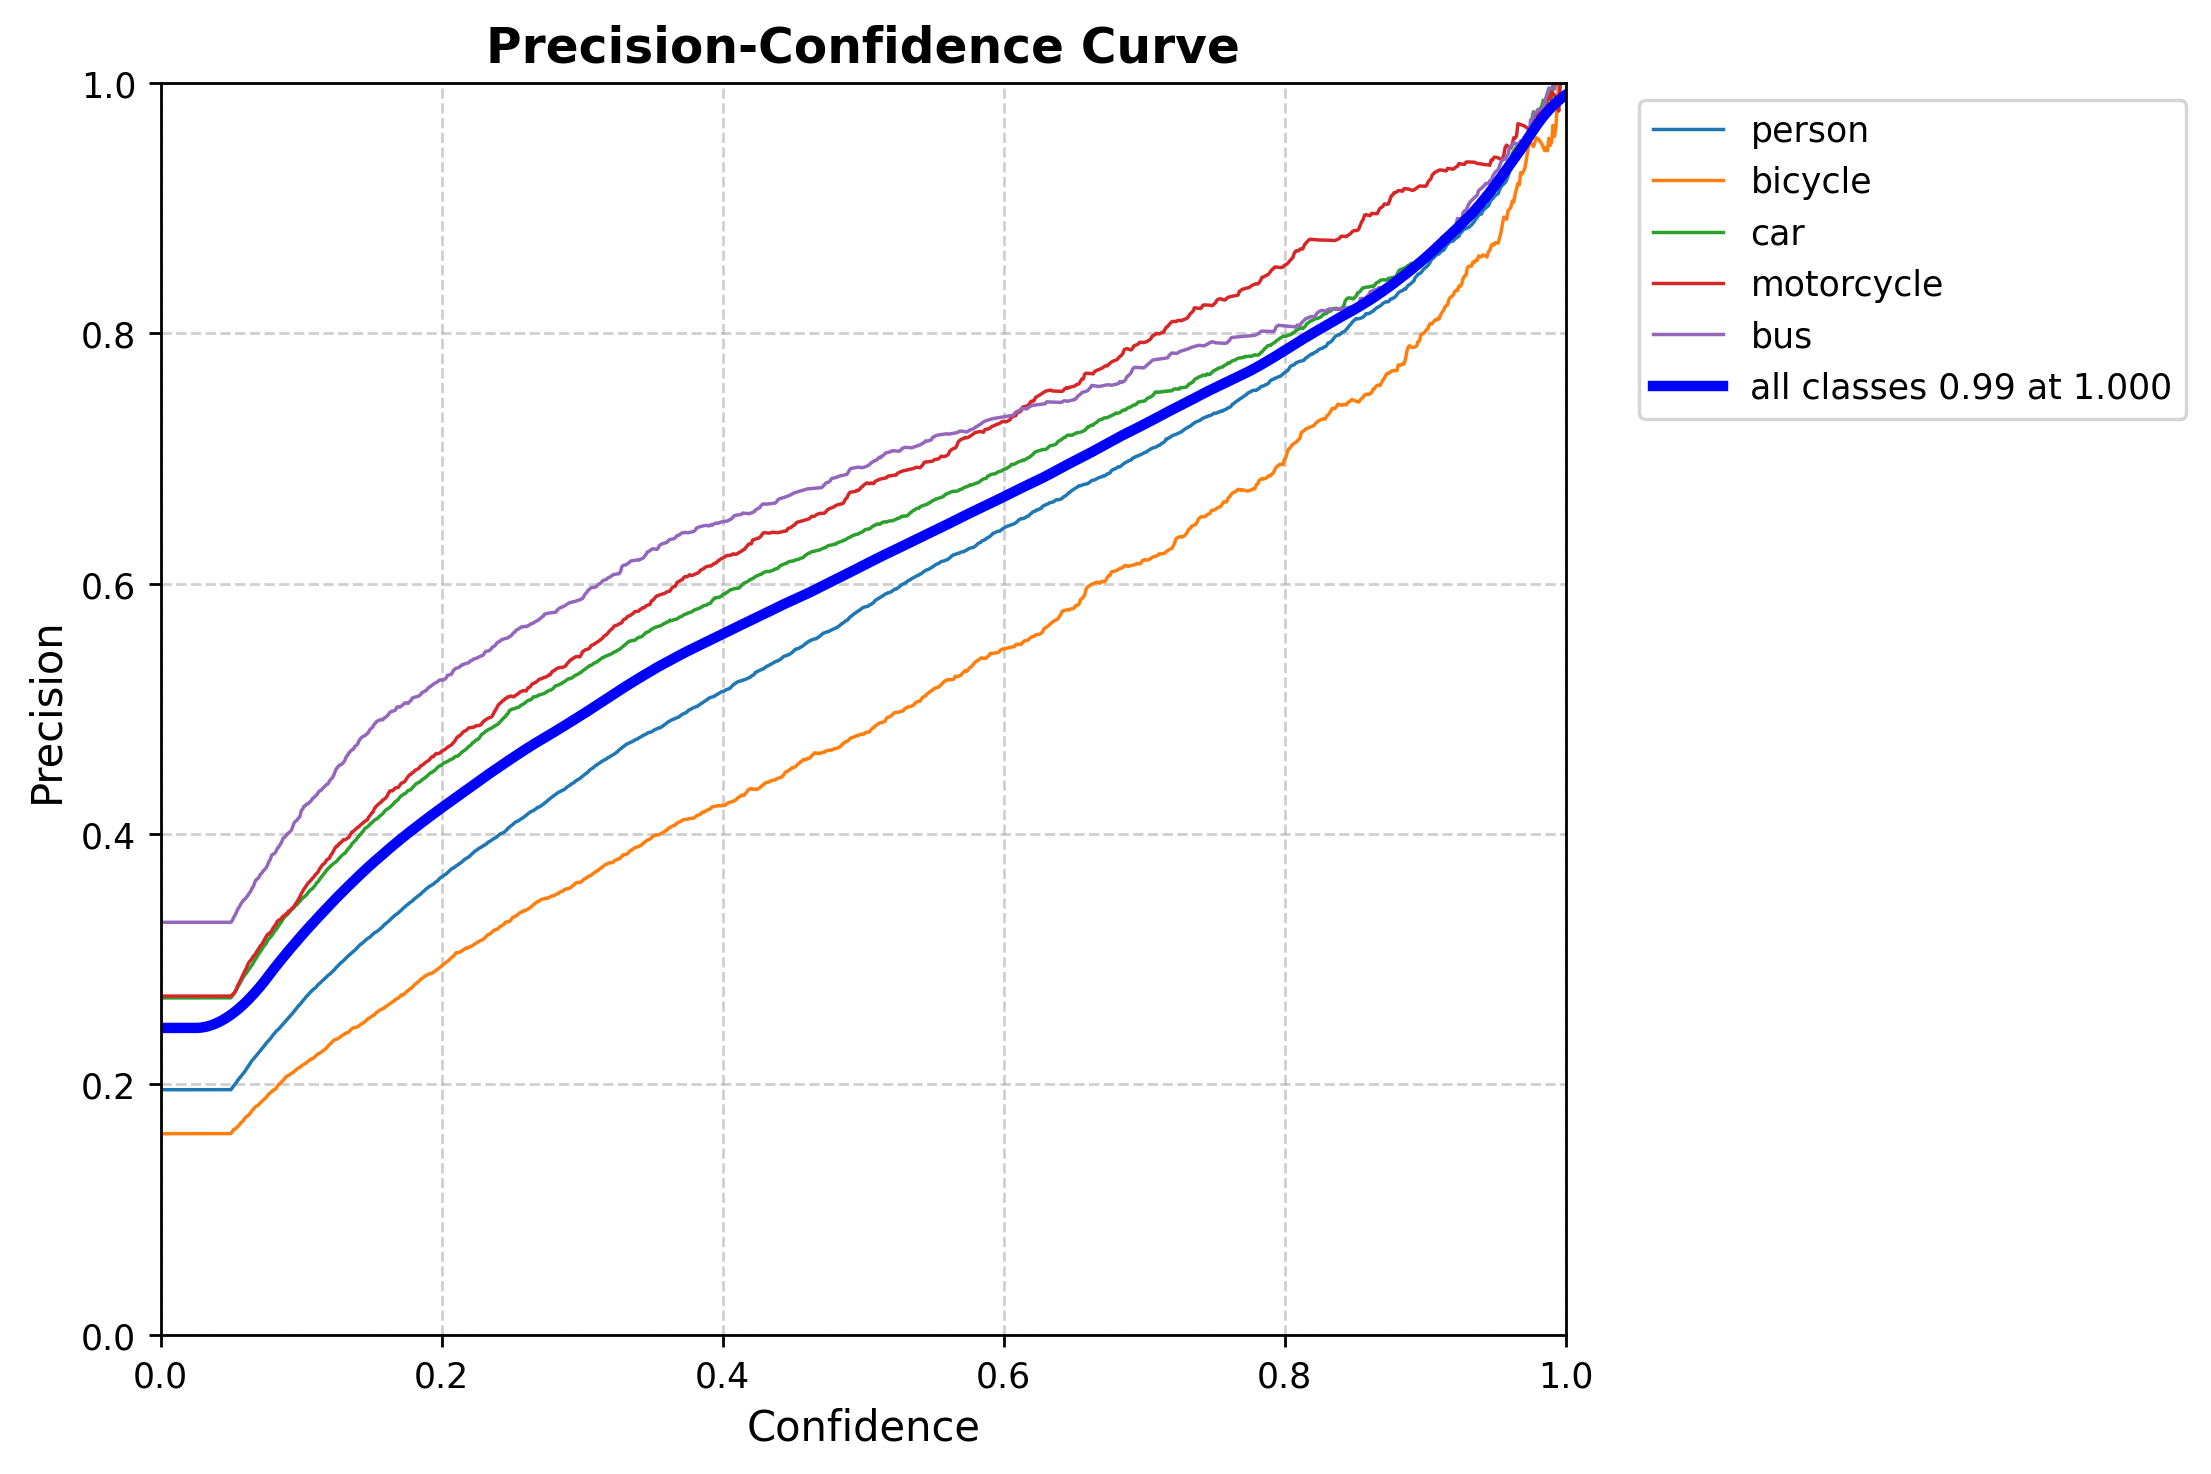

--------------------------------------------------


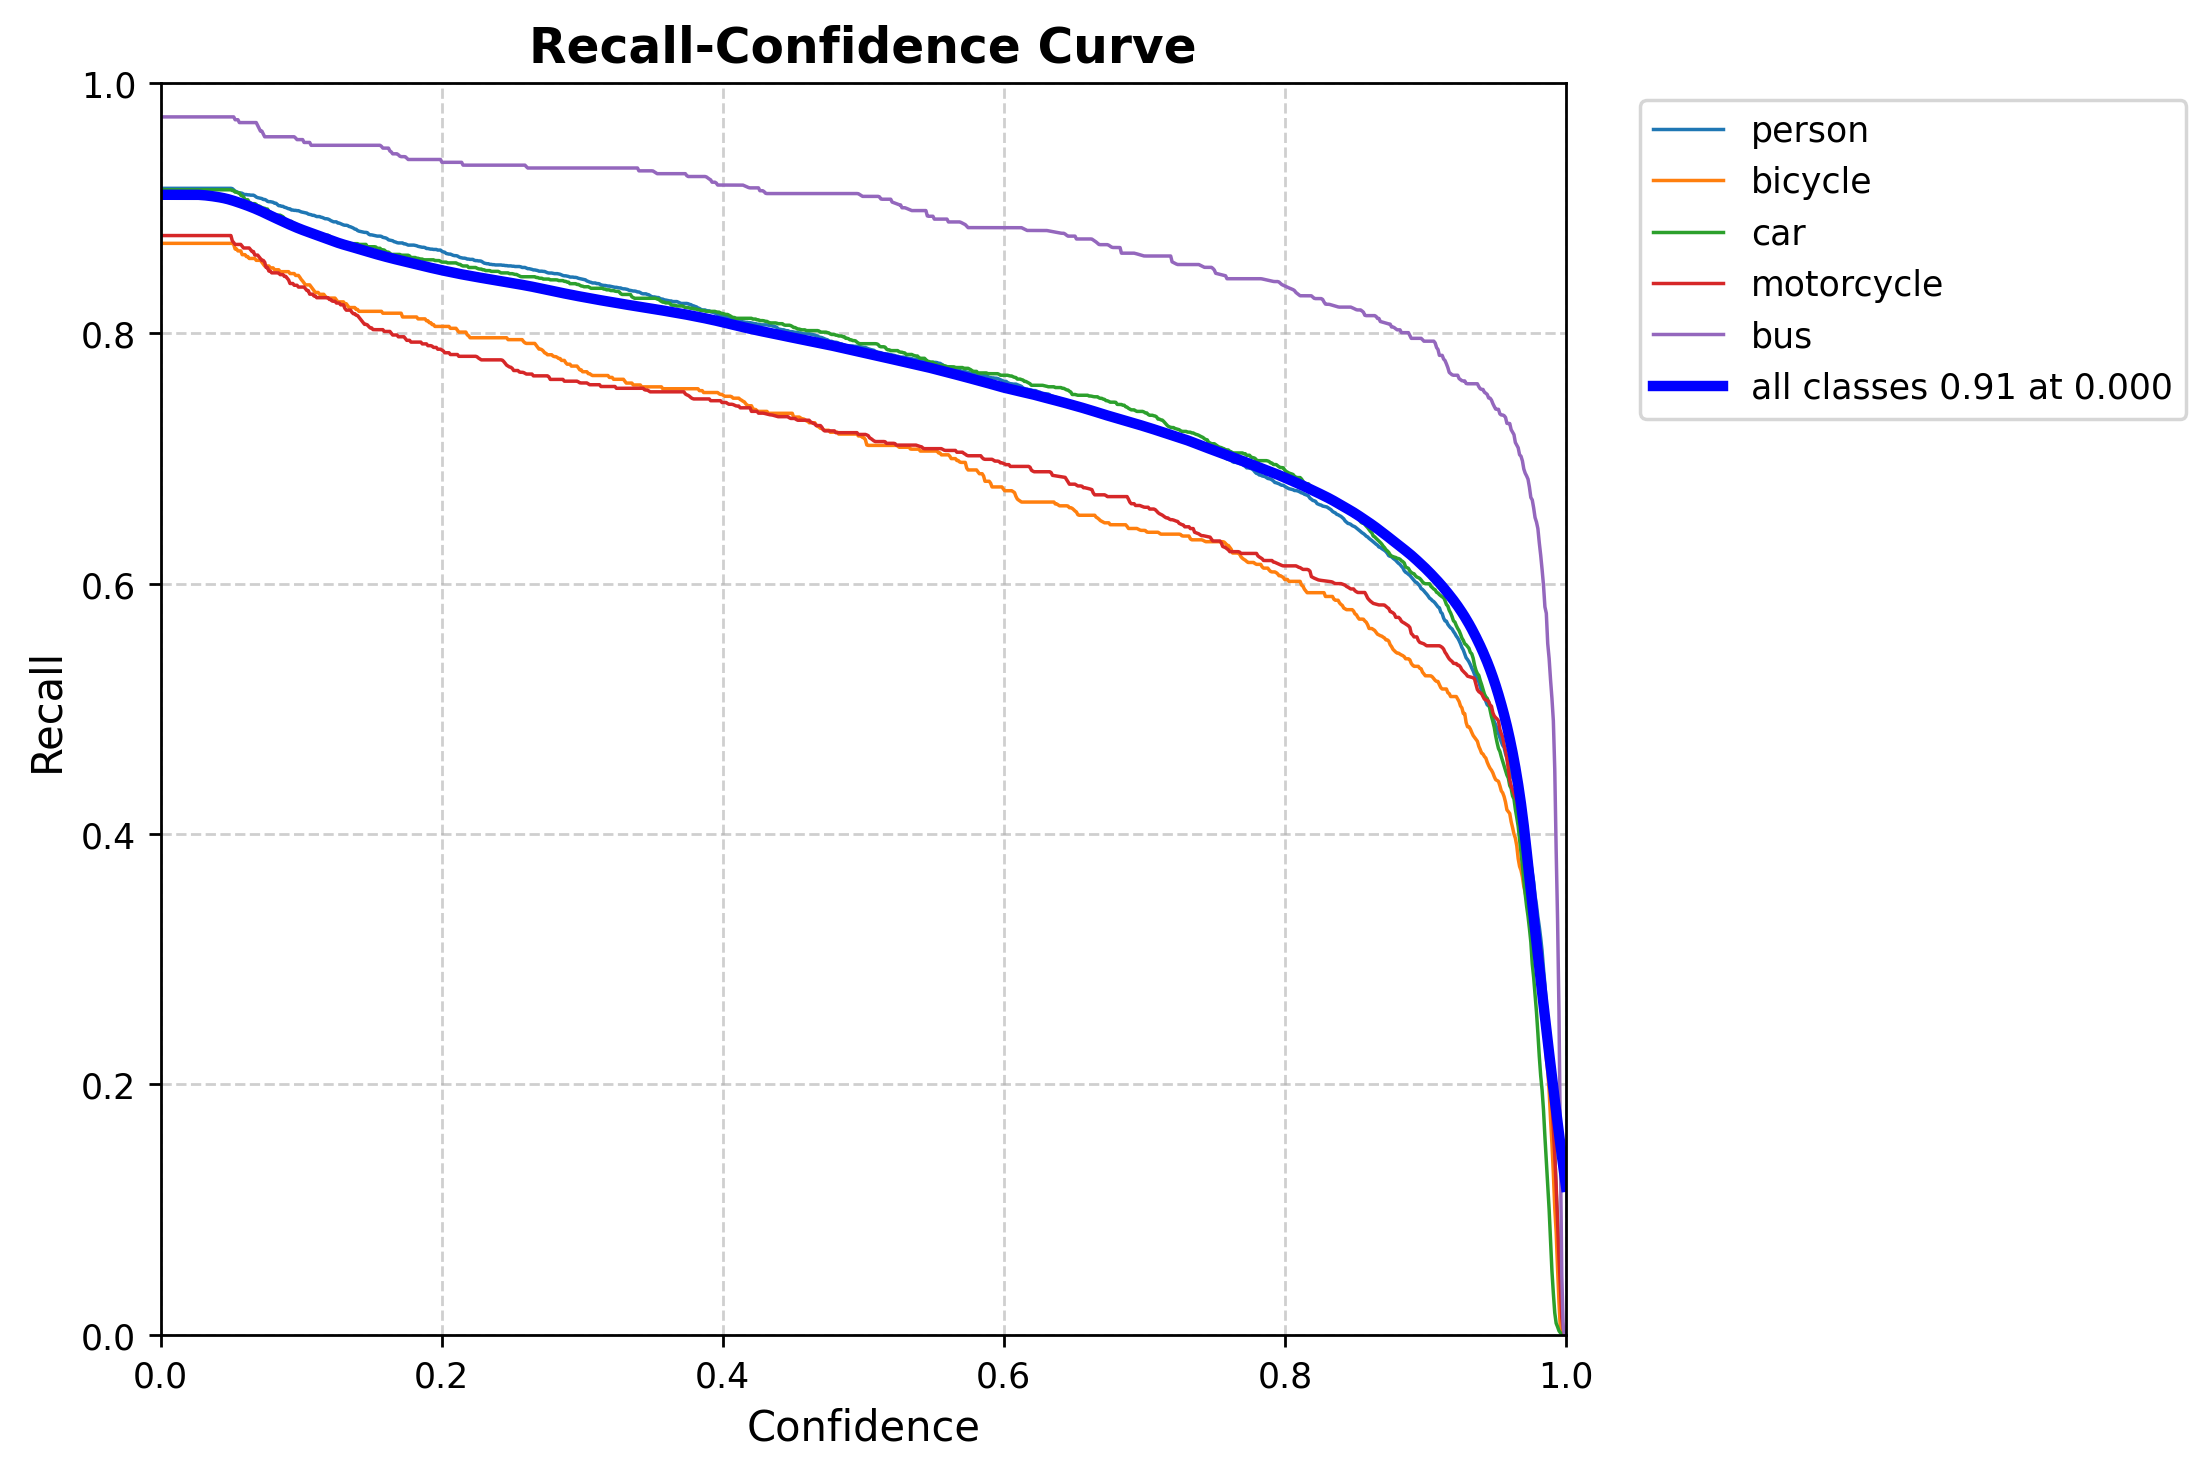

--------------------------------------------------


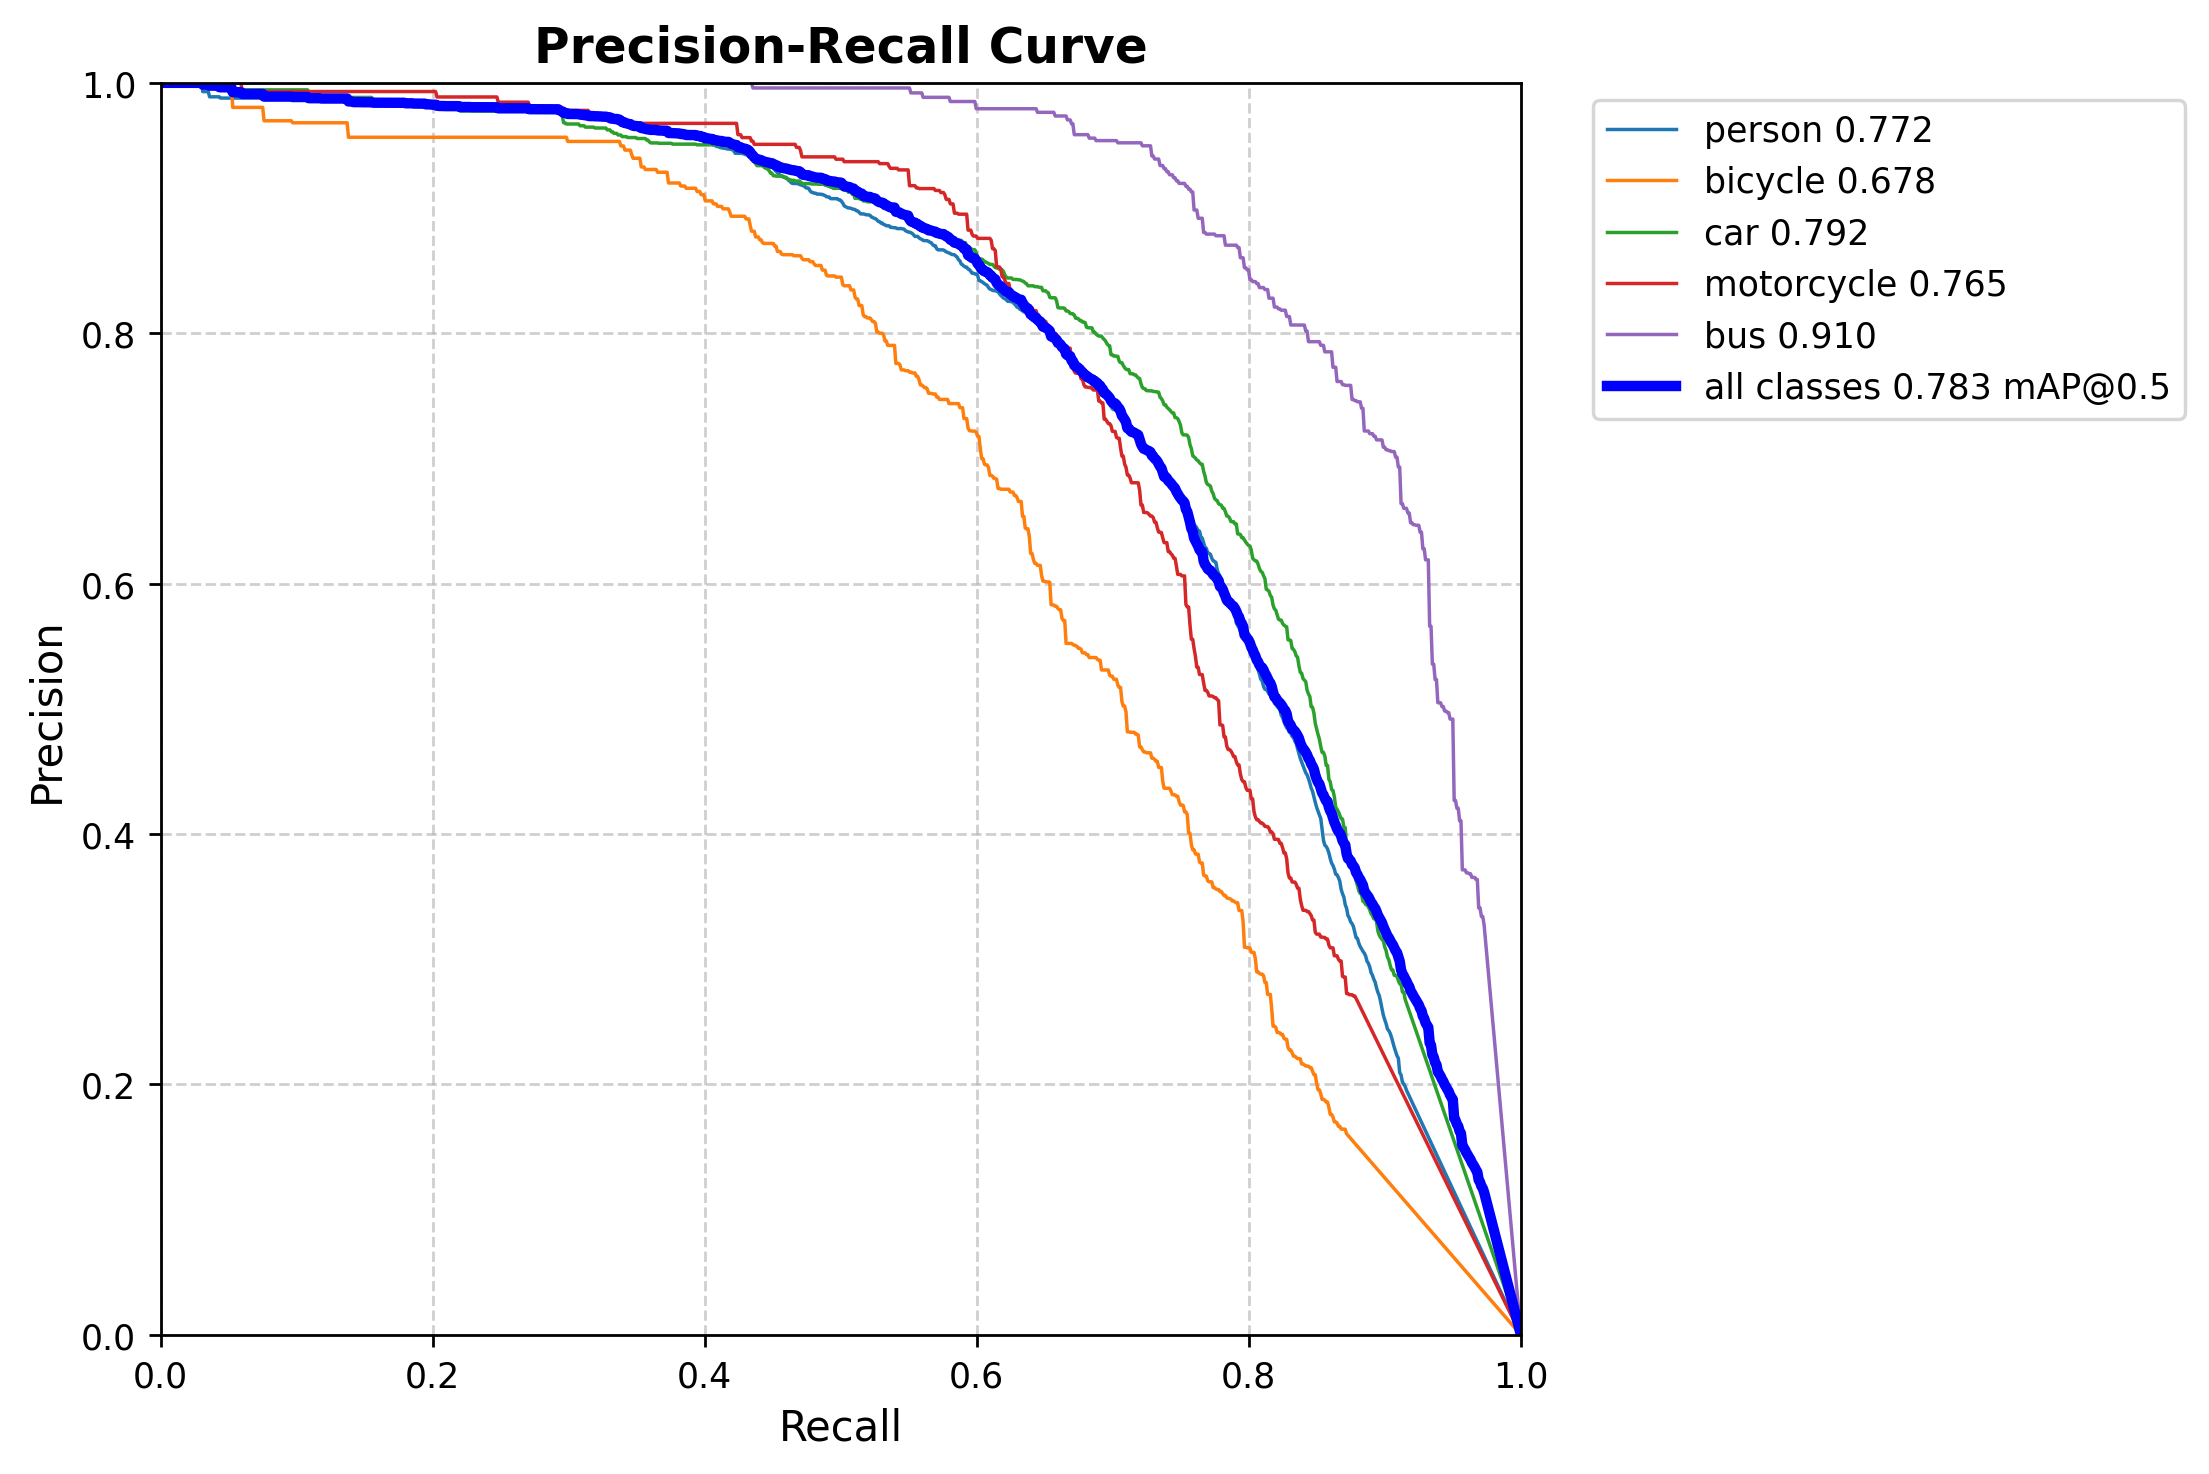

--------------------------------------------------


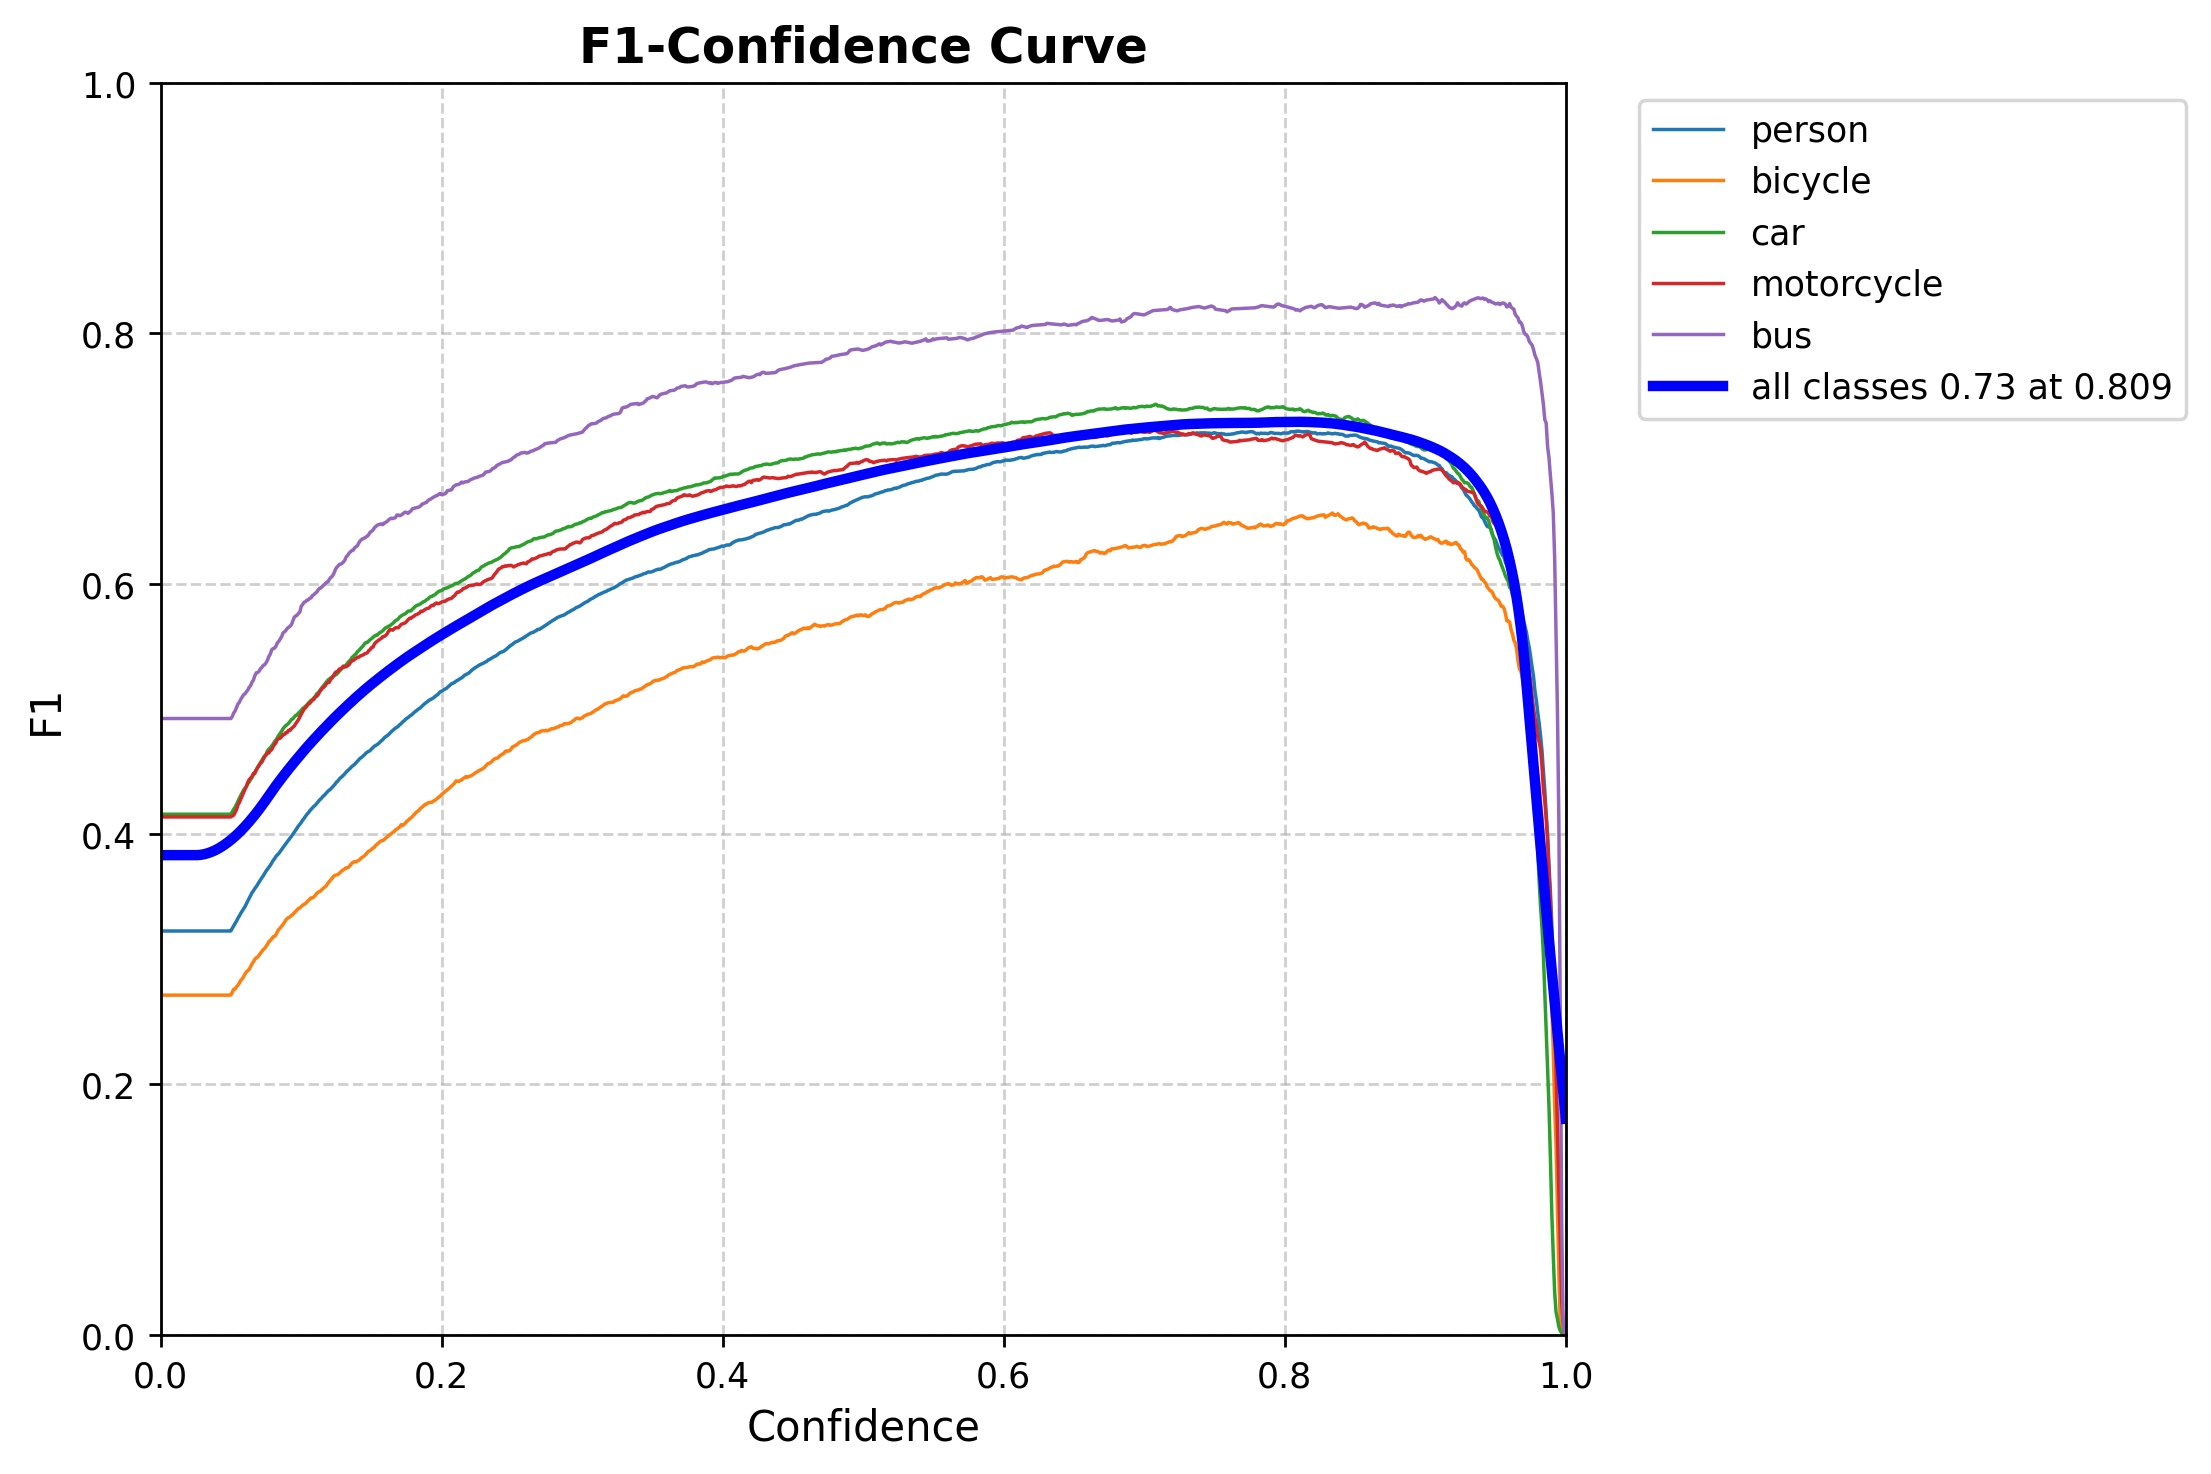

--------------------------------------------------
✅ Todos os gráficos foram exibidos com sucesso!


In [17]:
# ==============================================================================
# EXIBIÇÃO DOS GRÁFICOS GERADOS (IDÊNTICO AO Yolo5.ipynb)
# ==============================================================================
from IPython.display import display, Image, HTML

def mostrar_metrica(caminho_imagem, titulo):
    """Exibe a imagem usando o display nativo do IPython/Colab."""
    if os.path.exists(caminho_imagem):
        display(HTML(f"<h3 style='color: #2e6c80; font-family: sans-serif; margin-top: 20px;'>{titulo}</h3>"))
        display(Image(filename=caminho_imagem, width=800))
        print("-" * 50)
    else:
        print(f"⚠️ Métrica não encontrada no caminho: {caminho_imagem}")

print(f"📊 Visualizando gráficos de avaliação de: {pasta_saida_drive}")
print("=" * 70)

mostrar_metrica(os.path.join(pasta_saida_drive, "confusion_matrix.png"), "1. Matriz de Confusão (com Background)")
mostrar_metrica(os.path.join(pasta_saida_drive, "P_curve.png"), "2. Curva Precision vs Confiança")
mostrar_metrica(os.path.join(pasta_saida_drive, "R_curve.png"), "3. Curva Recall vs Confiança")
mostrar_metrica(os.path.join(pasta_saida_drive, "PR_curve.png"), "4. Curva Precision-Recall (mAP@0.5)")
mostrar_metrica(os.path.join(pasta_saida_drive, "F1_curve.png"), "5. Curva F1-Score vs Confiança")

print("✅ Todos os gráficos foram exibidos com sucesso!")


>>> GERANDO 3 AMOSTRAS COMPARATIVAS VISUAIS...


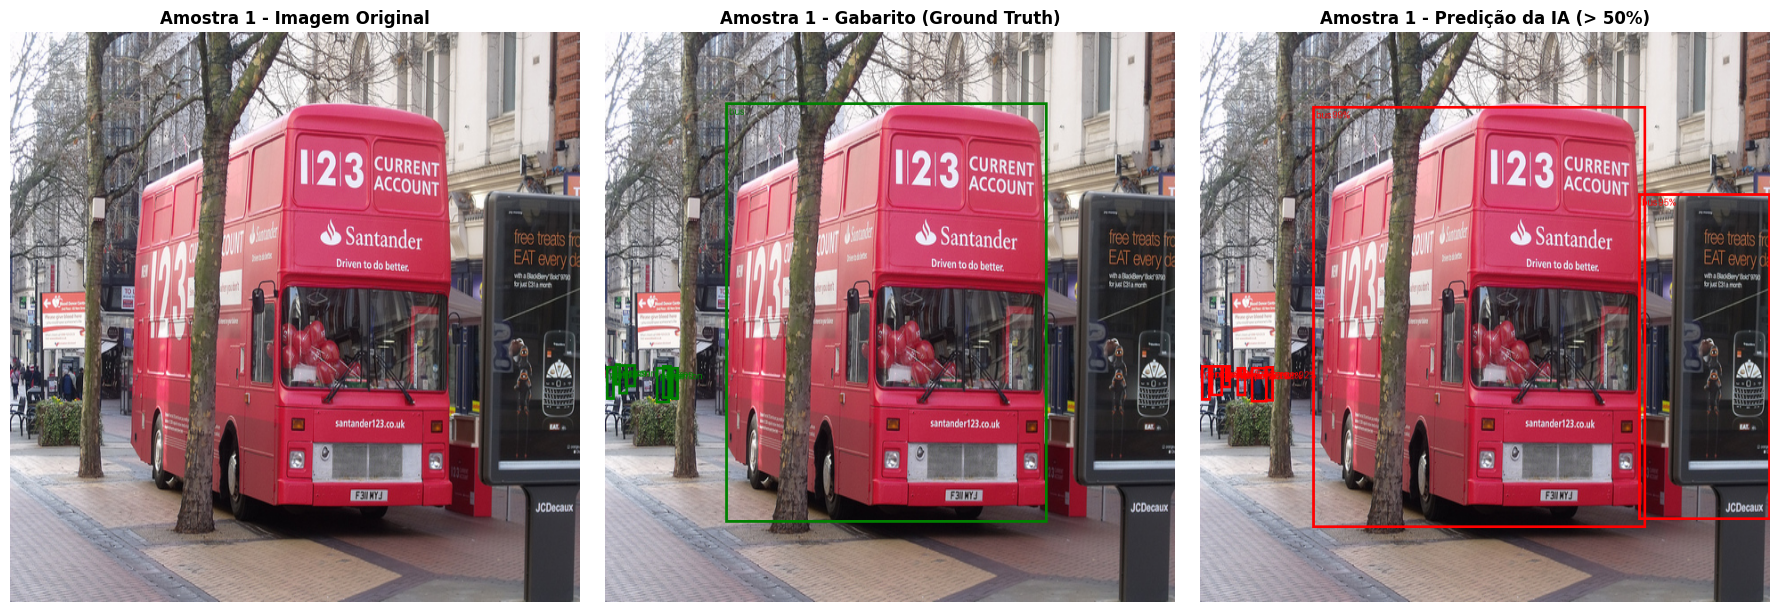

💾 Amostra salva em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-27_17h47/Teste_Final/amostra_comparativa_1.png


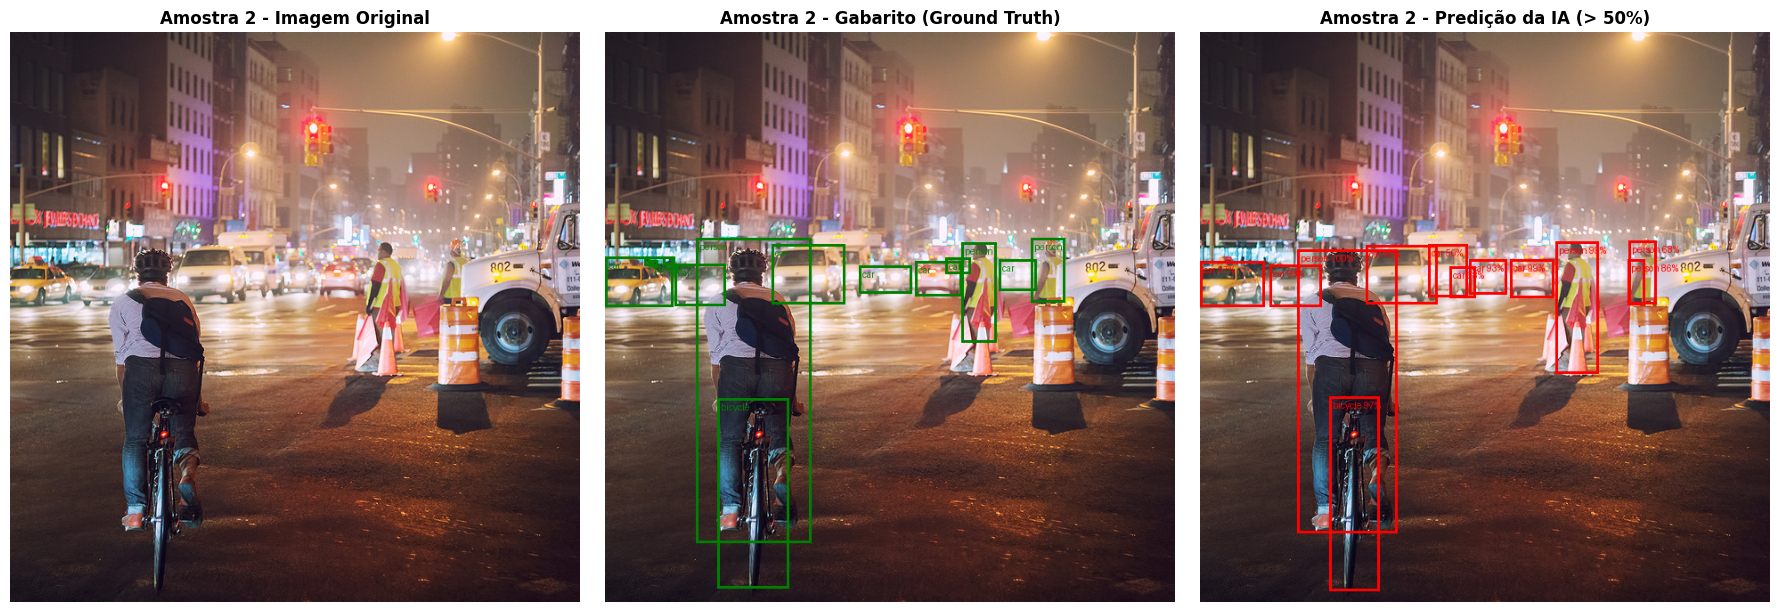

💾 Amostra salva em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-27_17h47/Teste_Final/amostra_comparativa_2.png


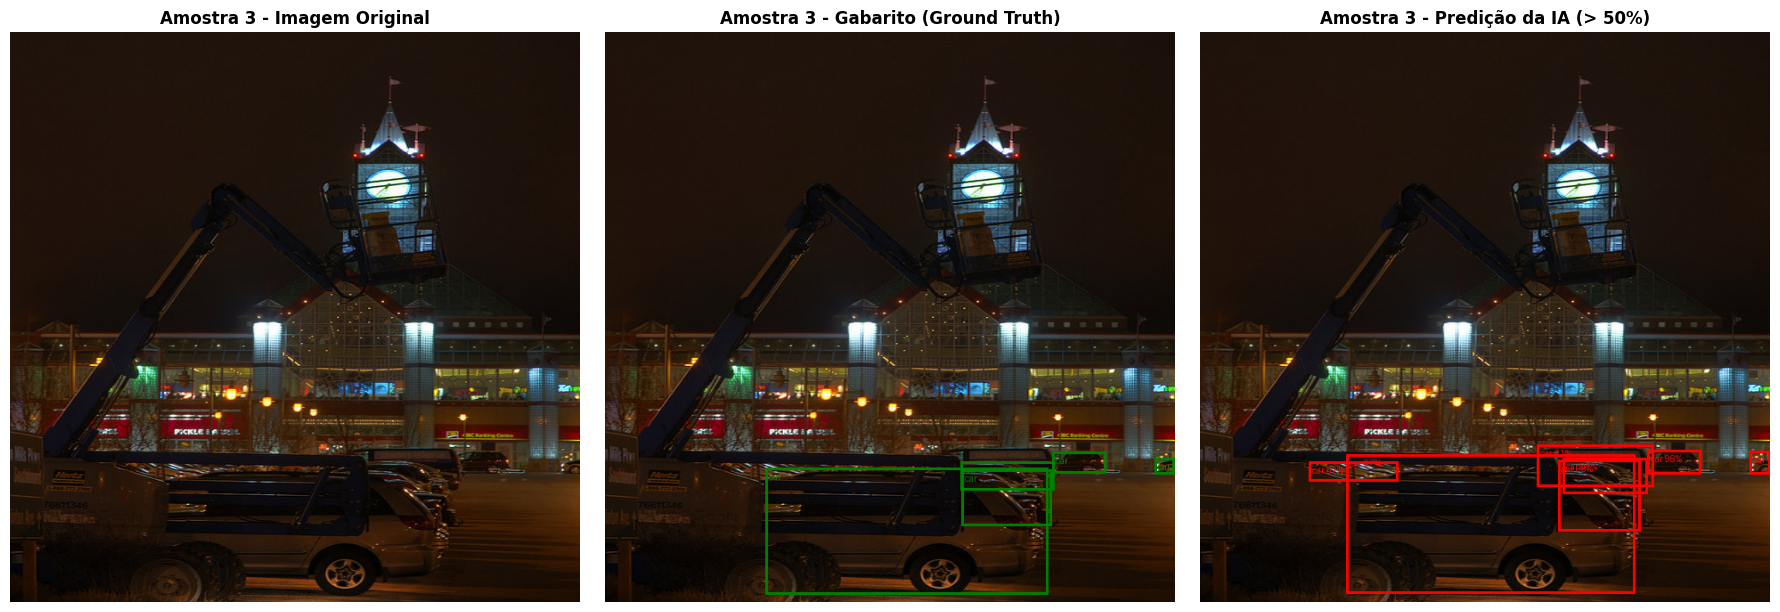

💾 Amostra salva em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-27_17h47/Teste_Final/amostra_comparativa_3.png


In [18]:
# ==============================================================================
# INFERÊNCIA PRÁTICA: AMOSTRAS COMPARATIVAS (Original vs Gabarito vs IA)
# ==============================================================================
import matplotlib.pyplot as plt
from torchvision.utils import draw_bounding_boxes
import random

def visualizar_amostras_comparativas(model, dataset, device, pasta_destino, num_amostras=3, limiar_confianca=0.5):
    model.eval()
    print(f">>> GERANDO {num_amostras} AMOSTRAS COMPARATIVAS VISUAIS...")
    
    indices = random.sample(range(len(dataset)), min(num_amostras, len(dataset)))
    
    for count, idx in enumerate(indices):
        img_tensor, target = dataset[idx]
        
        with torch.no_grad():
            output = model([img_tensor.to(device)])[0]
            
        img_uint8 = (img_tensor * 255).to(torch.uint8)
        
        # 1. Ground Truth
        boxes_gt = target["boxes"]
        if len(boxes_gt) > 0:
            labels_gt = [CLASS_NAMES.get(l.item() - 1, f"ID {l.item()}") for l in target["labels"]]
            img_gt = draw_bounding_boxes(img_uint8, boxes_gt, labels=labels_gt, colors="green", width=3)
        else:
            img_gt = img_uint8
            
        # 2. Predições
        pred_scores = output["scores"]
        limiar = limiar_confianca
        if len(pred_scores) > 0 and (pred_scores > limiar).sum() == 0:
            limiar = 0.15  # fallback para visualização
            
        keep = pred_scores >= limiar
        boxes_pred = output["boxes"][keep].cpu()
        scores_pred = pred_scores[keep].cpu()
        labels_pred = output["labels"][keep].cpu()
        
        if len(boxes_pred) > 0:
            labels_text = [
                f"{CLASS_NAMES.get(l.item() - 1, f'ID {l.item()}')} {s.item()*100:.0f}%"
                for l, s in zip(labels_pred, scores_pred)
            ]
            img_pred = draw_bounding_boxes(img_uint8, boxes_pred, labels=labels_text, colors="red", width=3)
        else:
            img_pred = img_uint8
            
        # 3. Plotagem lado a lado
        fig, ax = plt.subplots(1, 3, figsize=(18, 6))
        ax[0].imshow(img_uint8.permute(1, 2, 0).cpu().numpy())
        ax[0].set_title(f"Amostra {count + 1} - Imagem Original", fontsize=12, fontweight='bold')
        ax[0].axis("off")

        ax[1].imshow(img_gt.permute(1, 2, 0).cpu().numpy())
        ax[1].set_title(f"Amostra {count + 1} - Gabarito (Ground Truth)", fontsize=12, fontweight='bold')
        ax[1].axis("off")

        ax[2].imshow(img_pred.permute(1, 2, 0).cpu().numpy())
        ax[2].set_title(f"Amostra {count + 1} - Predição da IA (> {limiar*100:.0f}%)", fontsize=12, fontweight='bold')
        ax[2].axis("off")
        
        plt.tight_layout()
        caminho_amostra = os.path.join(pasta_destino, f"amostra_comparativa_{count + 1}.png")
        plt.savefig(caminho_amostra, bbox_inches="tight", dpi=150)
        plt.show()
        print(f"💾 Amostra salva em: {caminho_amostra}")

visualizar_amostras_comparativas(
    model,
    test_dataset,
    device,
    pasta_saida_drive,
    num_amostras=3,
    limiar_confianca=0.5
)
